In [6]:
!pip install tensorflow
!pip install xgboost

   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   --- ------------------------------------ 6.6/69.5 MB 39.8 MB/s eta 0:00:02
   ------ --------------------------------- 10.5/69.5 MB 28.4 MB/s eta 0:00:03
   -------- ------------------------------- 14.9/69.5 MB 25.3 MB/s eta 0:00:03
   ------------ --------------------------- 21.0/69.5 MB 26.1 MB/s eta 0:00:02
   --------------- ------------------------ 26.2/69.5 MB 26.0 MB/s eta 0:00:02
   ------------------ --------------------- 31.7/69.5 MB 26.0 MB/s eta 0:00:02
   ---------------------- ----------------- 39.1/69.5 MB 27.4 MB/s eta 0:00:02
   -------------------------- ------------- 46.1/69.5 MB 28.2 MB/s eta 0:00:01
   ------------------------------ --------- 53.7/69.5 MB 29.1 MB/s eta 0:00:01
   ----------------------------------- ---- 61.3/69.5 MB 29.8 MB/s eta 0:00:01
   ---------------------------------------  69.5/69.5 MB 30.7 MB/s eta 0:00:01
   ---------------------------------------- 69.5/69.5 MB 28.8 

In [7]:
import pandas as pd

madgraph_events = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold.h5")
sherpa_events = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_sherpa.h5")

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)


In [19]:
import numpy as np #array manipulation
import tensorflow as tf #neural network library
from sklearn.model_selection import train_test_split #splits dataset into training set and test set
from sklearn.preprocessing import StandardScaler

from tensorflow import keras
from tensorflow.keras import layers

observables = ['pT_ll', 'pT_l1', 'pT_l2', 'eta_l1', 'eta_l2', 'phi_l1', 'phi_l2', 'y_ll', 'pT_trackj1', 'y_trackj1',
               'phi_trackj1', 'm_trackj1', 'tau1_trackj1', 'tau2_trackj1', 'tau3_trackj1', 'pT_trackj2', 'y_trackj2',
               'phi_trackj2', 'm_trackj2', 'tau1_trackj2', 'tau2_trackj2', 'tau3_trackj2', 'Ntracks_trackj1', 
               'Ntracks_trackj2']


sherpa_features = sherpa_events[observables].values
madgraph_features = madgraph_events[observables].values

n_features = 24   # number of observables/columns you're using

scaler = StandardScaler()
X_all = np.concatenate((sherpa_features, madgraph_features))
scaler.fit(X_all)
sherpa_features_scaled = scaler.transform(sherpa_features)
madgraph_features_scaled = scaler.transform(madgraph_features)

import xgboost as xgb
from sklearn.metrics import roc_auc_score

X = np.concatenate((sherpa_features_scaled, madgraph_features_scaled))
y = np.concatenate((np.ones(len(sherpa_features)), np.zeros(len(madgraph_features))))

bdt = xgb.XGBClassifier(n_estimators=100, max_depth=4)
bdt.fit(X_train, y_train)

bdt_scores = bdt.predict_proba(X_test)[:, 1]   # probability of class 1 (Sherpa)
print("BDT AUC:", roc_auc_score(y_test, bdt_scores))

BDT AUC: 0.6865795424567567


AUC = 0.683 --> single number summary of everything above. (0.5 means classifier is no better than a coin flip, the diagonal line, and 1 means perfect separation)
    - confirms "overlapping but shifted" picture from image 2
    

In [20]:
import numpy as np #array manipulation
import tensorflow as tf #neural network library
from sklearn.model_selection import train_test_split #splits dataset into training set and test set
from sklearn.preprocessing import StandardScaler

from tensorflow import keras
from tensorflow.keras import layers

observables = ['pT_ll', 'pT_l1', 'pT_l2', 'eta_l1', 'eta_l2', 'phi_l1', 'phi_l2', 'y_ll', 'pT_trackj1', 'y_trackj1',
               'phi_trackj1', 'm_trackj1', 'tau1_trackj1', 'tau2_trackj1', 'tau3_trackj1', 'pT_trackj2', 'y_trackj2',
               'phi_trackj2', 'm_trackj2', 'tau1_trackj2', 'tau2_trackj2', 'tau3_trackj2', 'Ntracks_trackj1', 
               'Ntracks_trackj2']


sherpa_features = sherpa_events[observables].values
madgraph_features = madgraph_events[observables].values

n_features = 24   # number of observables/columns you're using

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')   # sigmoid output -> probability between 0 and 1
])

def train_classifier(sherpa_features, madgraph_features, model, epochs=20, batch_size=10000): #feature events, 
    #each row is one event, each column is one observable
    # label = 1 for Sherpa, 0 for MadGraph

    scaler = StandardScaler()
    X_all = np.concatenate((sherpa_features, madgraph_features))
    scaler.fit(X_all)
    sherpa_features_scaled = scaler.transform(sherpa_features)
    madgraph_features_scaled = scaler.transform(madgraph_features)

    
    X = np.concatenate((sherpa_features_scaled, madgraph_features_scaled)) #stacks every Sherpa event on top of every MadGraph event
    #into one big array (full set of inputs network will see)
    y = np.concatenate((np.ones(len(sherpa_features)), np.zeros(len(madgraph_features)))) #creates corresponding truth
    #labels: 1 for every row coming from Sherpa, 0 for every row coming from MadGraph

    model.compile(loss='binary_crossentropy',   # plain BCE -- no per-event weights needed 
                  #standard loss for 2-class problem (with sigmoid output)
                  #penalizes model based on how far its predicted probability was from the true label
                  #minimizing this loss is what makes model's output converge toward true probability that given event
                  #is sherpa vs Madgraph
                  optimizer='Adam', #algorithm that updates network's weights eaching training steo
                  metrics=['accuracy']) #if accuracy stays near 50%, both sims look statistically indistinguishable
    # if accuracy is well above 50%, there's real learnable structure differentiating them

    model.fit(X_train, y_train, #model runs through training data "epochs" times, updating weights via Adam to reduce
              #loss processing "batch_size" events at a time per gradient update
              epochs=epochs,
              batch_size=batch_size,
              validation_data=(X_test, y_test)) #evaluates loss/accuracy on test set without training on it
    #if training accuracy keeps climbing while validation accuracy plateaus or drops, that's overfitting warning sign

    history = model.fit(X_train, y_train,
                         epochs=epochs,
                         batch_size=batch_size,
                         validation_data=(X_test, y_test))
    return model, history, X_test, y_test

trained_model, history, X_test, y_test = train_classifier(sherpa_features, madgraph_features, model = model)

nn_test_scores = trained_model.predict(X_test).flatten()

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5825 - loss: 0.6734 - val_accuracy: 0.6011 - val_loss: 0.6628
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6097 - loss: 0.6573 - val_accuracy: 0.6137 - val_loss: 0.6535
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6210 - loss: 0.6489 - val_accuracy: 0.6216 - val_loss: 0.6471
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6264 - loss: 0.6438 - val_accuracy: 0.6261 - val_loss: 0.6439
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6302 - loss: 0.6410 - val_accuracy: 0.6280 - val_loss: 0.6417
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6327 - loss: 0.6390 - val_accuracy: 0.6304 - val_loss: 0.6399
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6342 - loss: 0.6376 - val_accuracy: 0.6326 - val_loss: 0.6386
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6352 - loss: 0.6364 - val_accuracy: 0.6333 - val_loss

AUC: 0.683


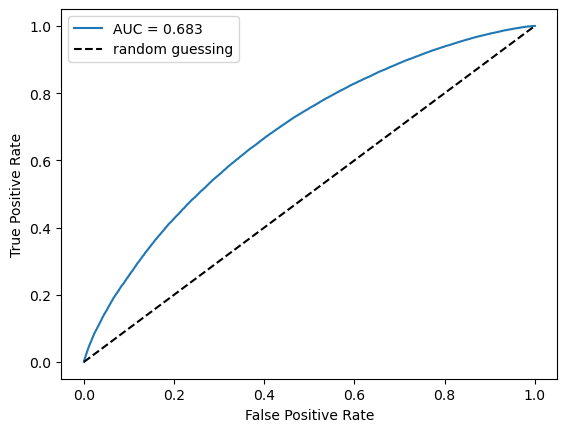

In [17]:
from sklearn.metrics import roc_auc_score, roc_curve

auc = roc_auc_score(y_test, nn_test_scores)
print(f"AUC: {auc:.3f}")

fpr, tpr, _ = roc_curve(y_test, nn_test_scores)
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0,1],[0,1],'k--', label='random guessing')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(); plt.show()

NN AUC: 0.682881432644238


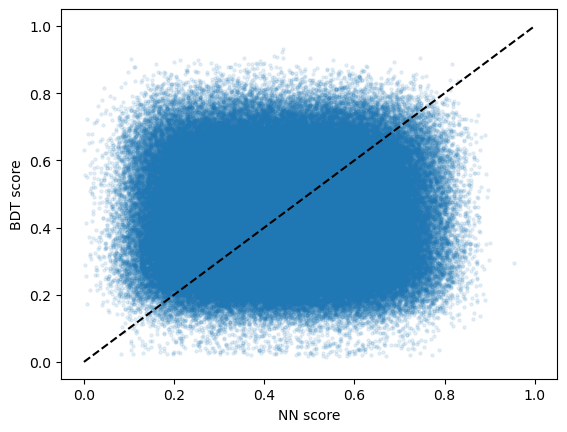

In [21]:
# ROC/AUC
from sklearn.metrics import roc_auc_score
print("NN AUC:", roc_auc_score(y_test, nn_test_scores))

# scatter comparison against the BDT
plt.scatter(nn_test_scores, bdt_test_scores, alpha=0.1, s=5)
plt.xlabel('NN score'); plt.ylabel('BDT score')
plt.plot([0,1],[0,1],'k--')
plt.show()